# DSC212 Research Assignment: Modularity on the Karate Club Graph

**Goal:** Implement recursive spectral modularity partitioning, visualize communities after each split, calculate four network metrics, and plot how the metrics change across iterations.
# Name : M SUNDRAMOORTHY
# Roll Number : IMS25279


## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

# Setting seed
SEED = 42

## 2. Load and inspect the graph

Number of nodes: 34
Number of edges: 78
Is the graph undirected? True


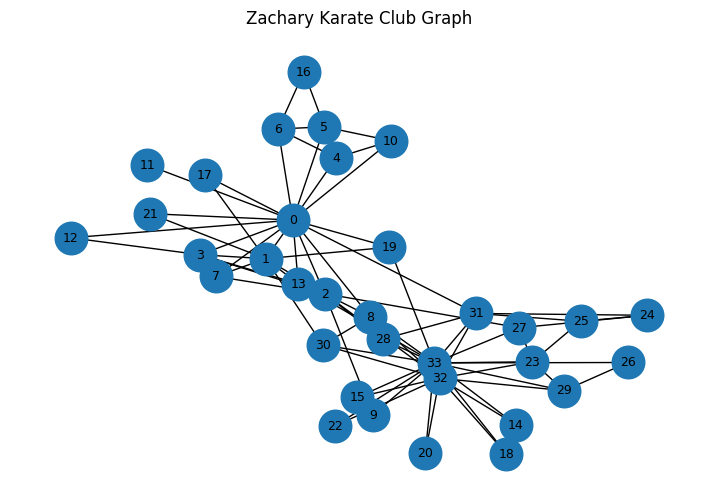

In [2]:
G = nx.karate_club_graph()

print(f"Number of nodes: {G.number_of_nodes()}")
print(f"Number of edges: {G.number_of_edges()}")
print(f"Is the graph undirected? {not G.is_directed()}")

pos = nx.spring_layout(G, seed=SEED)

plt.figure(figsize=(9, 6))
nx.draw_networkx(
    G, pos=pos, with_labels=True,
    node_size=550, font_size=9, width=1.0
)
plt.title("Zachary Karate Club Graph")
plt.axis("off")
plt.show()

## 3. Build the global modularity matrix

In [3]:
# Keep nodes in a consistent order.
nodes = list(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float, weight=None)
degrees = A.sum(axis=1)
m = G.number_of_edges()

B = A - np.outer(degrees, degrees) / (2 * m)

print("Adjacency matrix shape:", A.shape)
print("Adjacency matrix contains only 0 and 1:", set(np.unique(A)).issubset({0.0, 1.0}))
print("Modularity matrix shape:", B.shape)
print("Symmetric:", np.allclose(B, B.T))
print("Maximum absolute row sum (approximately 0):", np.abs(B.sum(axis=1)).max())

Adjacency matrix shape: (34, 34)
Adjacency matrix contains only 0 and 1: True
Modularity matrix shape: (34, 34)
Symmetric: True
Maximum absolute row sum (approximately 0): 8.881784197001252e-16


## 4. Recursive spectral bisection


In [ ]:
def recursive_spectral_partition(B_global, node_list, max_communities=None, min_size=2):

    node_to_index = {node: i for i, node in enumerate(node_list)}
    communities = [list(node_list)]
    snapshots = [{node: 0 for node in node_list}]
    split_log = []

    while True:
        if max_communities is not None and len(communities) >= max_communities:
            break

        # Find the first community with a positive leading eigenvalue
        # AND a valid sign-based split into two non-empty groups.
        candidate_index = None
        candidate_eigenvalue = None
        candidate_eigenvector = None

        for idx, community in enumerate(communities):
            if len(community) < min_size:
                continue

            indices = [node_to_index[node] for node in community]
            B_C = B_global[np.ix_(indices, indices)]
            eigenvalues, eigenvectors = np.linalg.eigh(B_C)
            largest_index = int(np.argmax(eigenvalues))
            largest_value = float(eigenvalues[largest_index])
            leading_vector = eigenvectors[:, largest_index]

            positive_group = [
                node for node, value in zip(community, leading_vector)
                if value > 0
            ]
            negative_group = [
                node for node, value in zip(community, leading_vector)
                if value <= 0
            ]

            if largest_value <= 1e-10:
                split_log.append({
                    "community_size": len(community),
                    "nodes_tested": tuple(community),
                    "largest_eigenvalue": largest_value,
                    "action": "stopped: leading eigenvalue nonpositive"
                })
                continue

            if not positive_group or not negative_group:
                split_log.append({
                    "community_size": len(community),
                    "nodes_tested": tuple(community),
                    "largest_eigenvalue": largest_value,
                    "action": "not split: sign rule produced an empty group"
                })
                continue

            candidate_index = idx
            candidate_eigenvalue = largest_value
            candidate_eigenvector = leading_vector
            break

        # No remaining community has a valid positive-eigenvalue sign split.
        if candidate_index is None:
            break

        community = communities.pop(candidate_index)
        positive_group = [
            node for node, value in zip(community, candidate_eigenvector)
            if value > 0
        ]
        negative_group = [
            node for node, value in zip(community, candidate_eigenvector)
            if value <= 0
        ]

        communities.insert(candidate_index, negative_group)
        communities.insert(candidate_index, positive_group)

        split_log.append({
            "community_size": len(community),
            "nodes_tested": tuple(community),
            "largest_eigenvalue": candidate_eigenvalue,
            "action": f"split into sizes {len(positive_group)} and {len(negative_group)}"
        })

        # Save the current partition as a node -> community-ID mapping.
        labels = {}
        for community_id, group in enumerate(communities):
            for node in group:
                labels[node] = community_id
        snapshots.append(labels.copy())

    return snapshots, split_log

snapshots, split_log = recursive_spectral_partition(B, nodes)

print(f"Number of accepted splits: {len(snapshots) - 1}")
print(f"Final number of communities: {len(set(snapshots[-1].values()))}")
print("Community sizes in final partition:",
      sorted([sum(label == cid for label in snapshots[-1].values())
              for cid in set(snapshots[-1].values())]))

Number of accepted splits: 4
Final number of communities: 5
Community sizes in final partition: [1, 5, 5, 10, 13]


## 5. Inspect the split history

In [5]:
split_history = pd.DataFrame(split_log)
display(split_history[["community_size", "largest_eigenvalue", "action"]])

,community_size,largest_eigenvalue,action
0,34,4.977080,split into sizes 16 and 18
1,16,2.944129,split into sizes 10 and 6
2,10,2.571158,not split: sign rule produced an empty group
3,6,2.147993,split into sizes 1 and 5
4,10,2.571158,not split: sign rule produced an empty group
5,5,2.147005,not split: sign rule produced an empty group
6,18,2.504088,split into sizes 5 and 13
7,10,2.571158,not split: sign rule produced an empty group
8,5,2.147005,not split: sign rule produced an empty group
9,5,1.875925,not split: sign rule produced an empty group


## 6. Visualize the graph after each accepted split

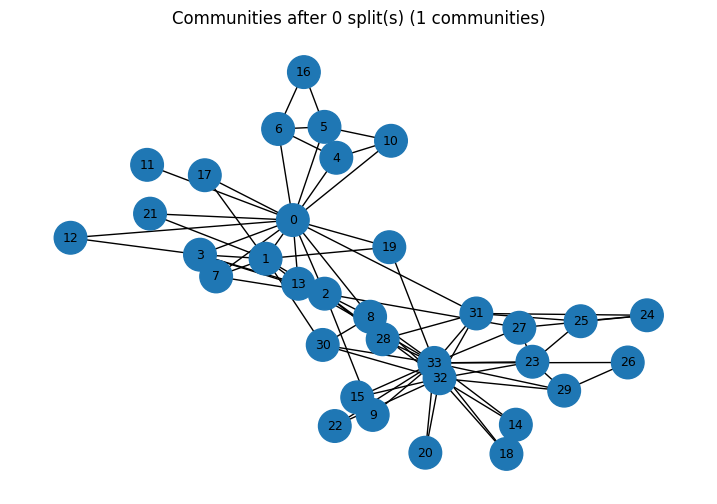

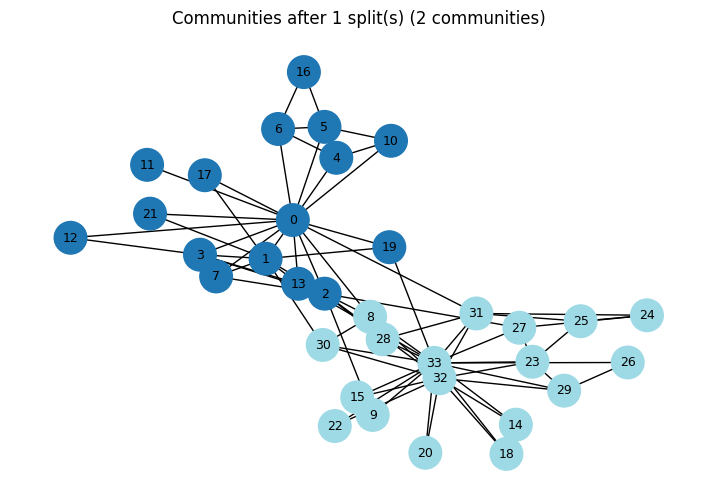

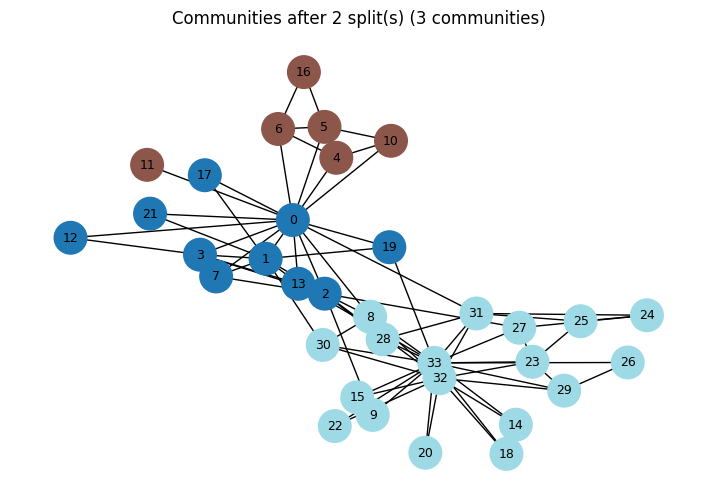

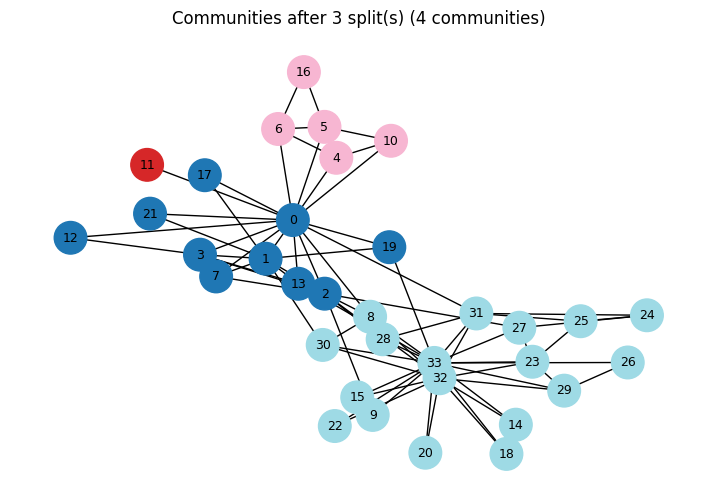

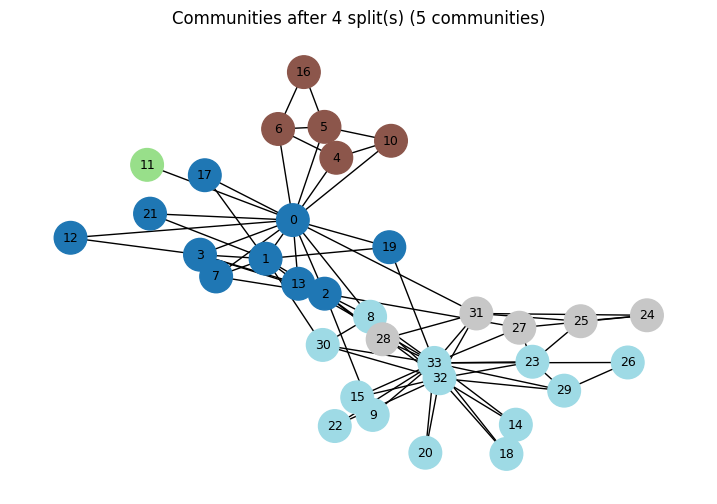

In [6]:
for iteration, labels in enumerate(snapshots):
    node_colors = [labels[node] for node in nodes]
    plt.figure(figsize=(9, 6))
    nx.draw_networkx(
        G, pos=pos, nodelist=nodes, node_color=node_colors,
        cmap=plt.cm.tab20, vmin=0, vmax=max(1, max(node_colors)),
        with_labels=True, node_size=550, font_size=9, width=1.0
    )
    plt.title(f"Communities after {iteration} split(s) "
              f"({len(set(labels.values()))} communities)")
    plt.axis("off")
    plt.show()

## 7. Calculate metrics on the original graph (constant across splits)


In [ ]:
metric_functions = {
    "Degree centrality": nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality": nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

# Compute and store the metrics after each accepted split.
# NetworkX function calls in the assignment, so values remain unchanged.
metric_values_history = {
    iteration: {
        metric_name: function(G)
        for metric_name, function in metric_functions.items()
    }
    for iteration in range(len(snapshots))
}

metric_values = metric_values_history[len(snapshots) - 1]

# Table of metric values for every node.
metrics_df = pd.DataFrame({
    "Node": nodes,
    **{
        metric_name: [values[node] for node in nodes]
        for metric_name, values in metric_values.items()
    }
})
display(metrics_df.round(4))

,Node,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient
0,0,0.4848,0.4376,0.5690,0.1500
1,1,0.2727,0.0539,0.4853,0.3333
2,2,0.3030,0.1437,0.5593,0.2444
3,3,0.1818,0.0119,0.4648,0.6667
4,4,0.0909,0.0006,0.3793,0.6667
5,5,0.1212,0.0300,0.3837,0.5000
6,6,0.1212,0.0300,0.3837,0.5000
7,7,0.1212,0.0000,0.4400,1.0000
8,8,0.1515,0.0559,0.5156,0.5000
9,9,0.0606,0.0008,0.4342,0.0000


## 8. Plot metric evolution across iterations

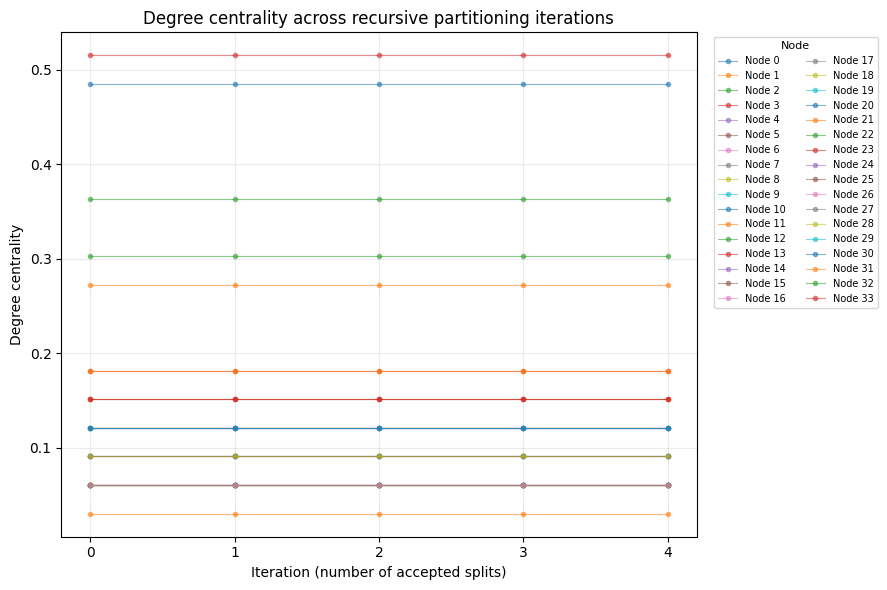

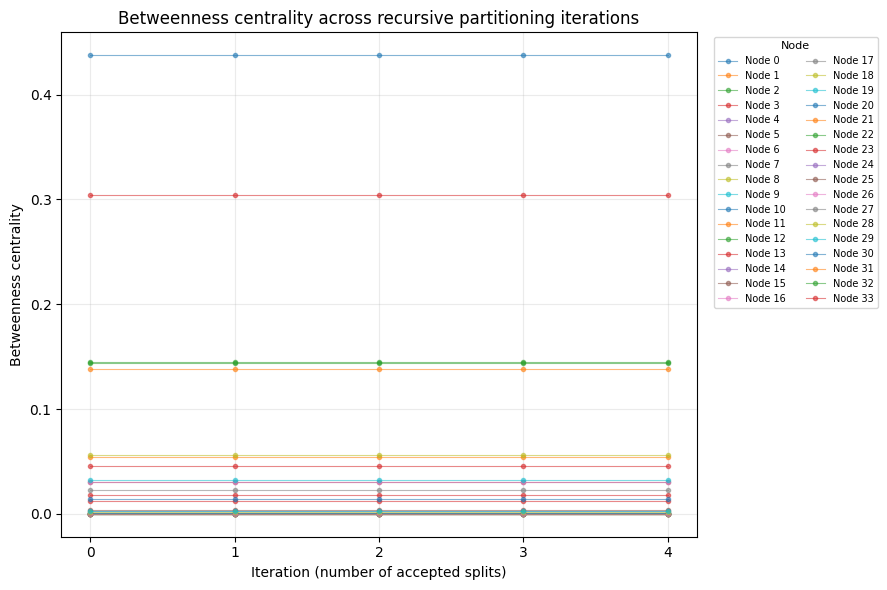

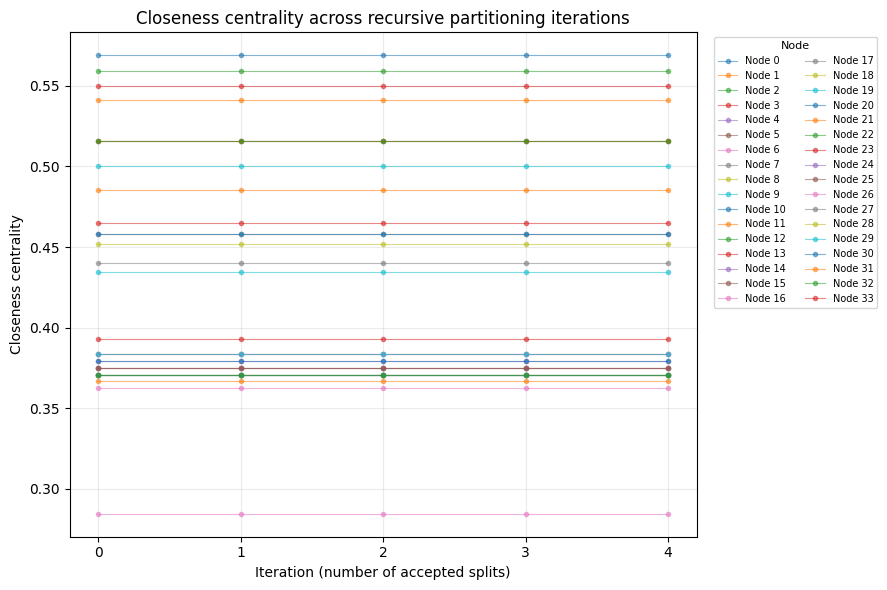

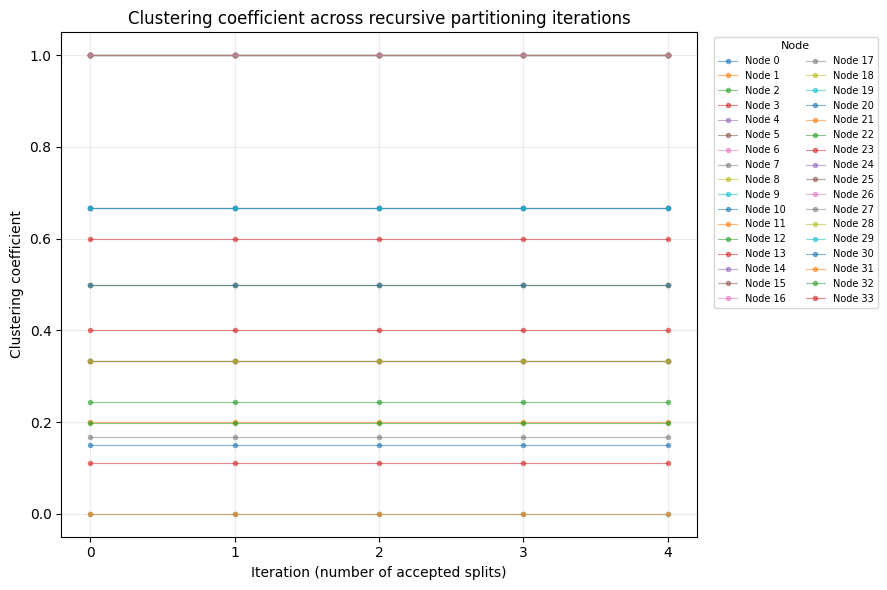

In [8]:
iterations = list(range(len(snapshots)))

for metric_name in metric_functions:
    plt.figure(figsize=(11, 6))
    for node in nodes:
        y_values = [
            metric_values_history[iteration][metric_name][node]
            for iteration in iterations
        ]
        plt.plot(iterations, y_values, marker=".", linewidth=0.8, alpha=0.55,
                 label=f"Node {node}")
    plt.xlabel("Iteration (number of accepted splits)")
    plt.ylabel(metric_name)
    plt.title(f"{metric_name} across recursive partitioning iterations")
    plt.xticks(iterations)
    plt.grid(True, alpha=0.25)
    plt.legend(title="Node", bbox_to_anchor=(1.02, 1), loc="upper left",
               fontsize=7, title_fontsize=8, ncol=2)
    plt.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()

## 9. Metrics within each assigned community

To show how the measures can change when the community structure is taken into account

Community-relative metric values (first 15 rows):


,Iteration,Node,Community,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient
0,0,0,0,0.4848,0.4376,0.5690,0.1500
1,0,1,0,0.2727,0.0539,0.4853,0.3333
2,0,2,0,0.3030,0.1437,0.5593,0.2444
3,0,3,0,0.1818,0.0119,0.4648,0.6667
4,0,4,0,0.0909,0.0006,0.3793,0.6667
5,0,5,0,0.1212,0.0300,0.3837,0.5000
6,0,6,0,0.1212,0.0300,0.3837,0.5000
7,0,7,0,0.1212,0.0000,0.4400,1.0000
8,0,8,0,0.1515,0.0559,0.5156,0.5000
9,0,9,0,0.0606,0.0008,0.4342,0.0000


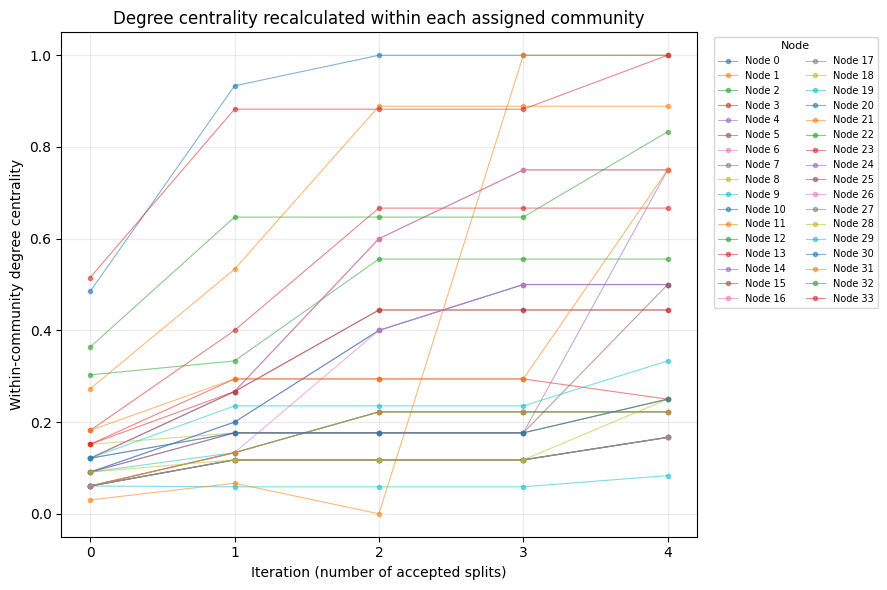

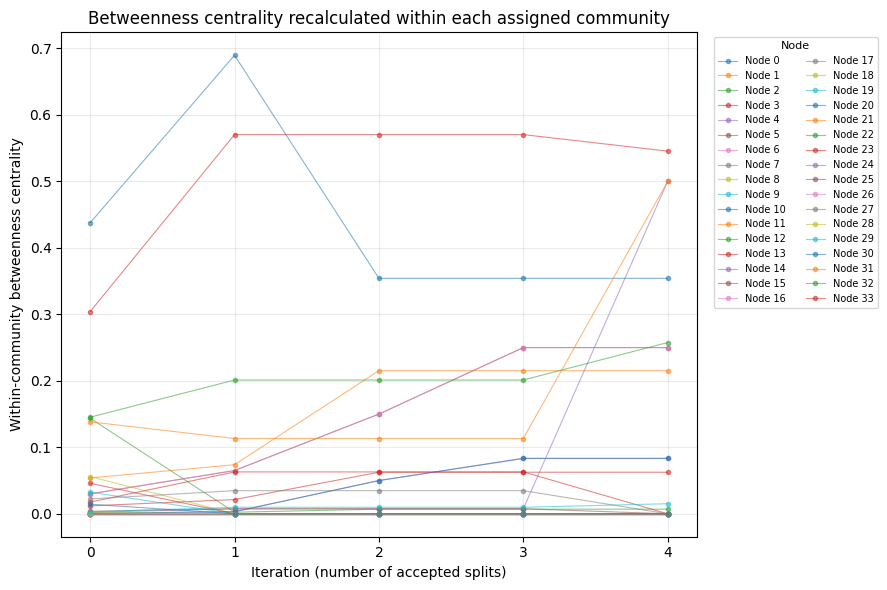

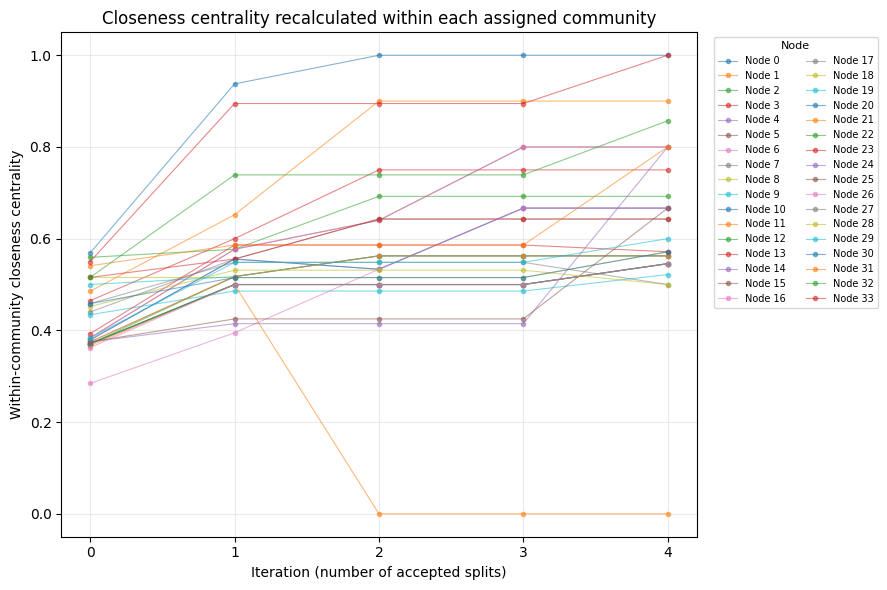

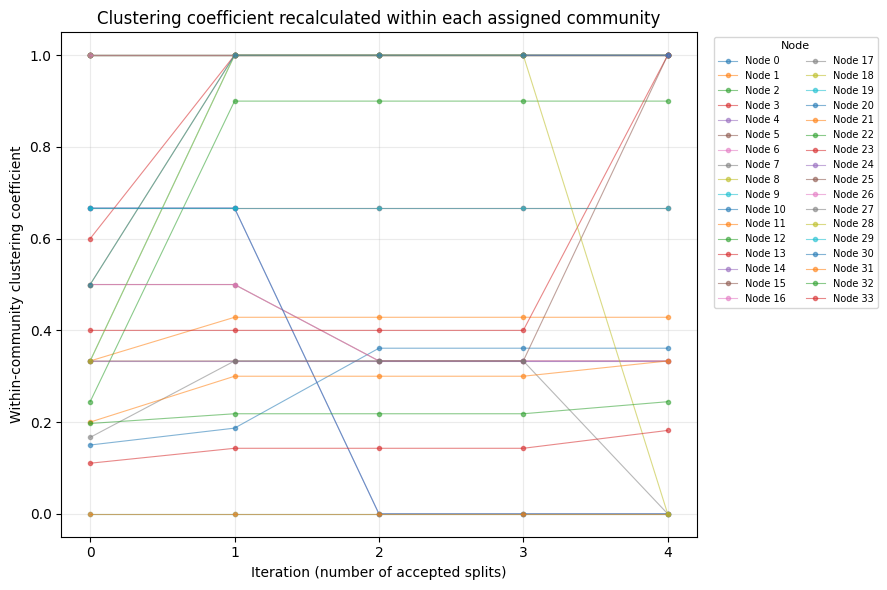

Number of nodes whose within-community metric changed at each split:


,From iteration,To iteration,Degree centrality,Betweenness centrality,Closeness centrality,Clustering coefficient
0,0,1,34,22,34,12
1,1,2,16,8,16,5
2,2,3,6,4,5,0
3,3,4,18,8,18,7


In [ ]:

# Each node receives the metric value from the induced subgraph of its current community.
community_metric_history = {}
community_metric_rows = []

for iteration, labels in enumerate(snapshots):
    per_metric = {metric_name: {} for metric_name in metric_functions}
    community_ids = sorted(set(labels.values()))

    for community_id in community_ids:
        community_nodes = [node for node in nodes if labels[node] == community_id]
        community_graph = G.subgraph(community_nodes).copy()
        for metric_name, function in metric_functions.items():
            values = function(community_graph)
            per_metric[metric_name].update(values)

    community_metric_history[iteration] = per_metric
    for node in nodes:
        row = {"Iteration": iteration, "Node": node,
               "Community": labels[node]}
        for metric_name in metric_functions:
            row[metric_name] = per_metric[metric_name][node]
        community_metric_rows.append(row)

community_metrics_long_df = pd.DataFrame(community_metric_rows)
print("Community-relative metric values (first 15 rows):")
display(community_metrics_long_df.head(15).round(4))

# Plot the within-community value of each metric for every node across stages.
for metric_name in metric_functions:
    plt.figure(figsize=(11, 6))
    for node in nodes:
        y_values = [community_metric_history[it][metric_name][node]
                    for it in range(len(snapshots))]
        plt.plot(range(len(snapshots)), y_values, marker=".",
                 linewidth=0.8, alpha=0.55, label=f"Node {node}")
    plt.xlabel("Iteration (number of accepted splits)")
    plt.ylabel(f"Within-community {metric_name.lower()}")
    plt.title(f"{metric_name} recalculated within each assigned community")
    plt.xticks(range(len(snapshots)))
    plt.grid(True, alpha=0.25)
    plt.legend(title="Node", bbox_to_anchor=(1.02, 1), loc="upper left",
               fontsize=7, title_fontsize=8, ncol=2)
    plt.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()

# Compact change summary: count how many nodes changed value from the previous stage.
change_rows = []
for iteration in range(1, len(snapshots)):
    row = {"From iteration": iteration - 1, "To iteration": iteration}
    for metric_name in metric_functions:
        changed = sum(
            not np.isclose(
                community_metric_history[iteration - 1][metric_name][node],
                community_metric_history[iteration][metric_name][node]
            ) for node in nodes
        )
        row[metric_name] = changed
    change_rows.append(row)

community_metric_change_summary = pd.DataFrame(change_rows)
print("Number of nodes whose within-community metric changed at each split:")
display(community_metric_change_summary)


## 10. Identify consistently central nodes

In [10]:
# Rank nodes by each metric in the original graph.
for metric_name in metric_values:
    ranked = metrics_df[["Node", metric_name]].sort_values(
        metric_name, ascending=False
    ).head(10)
    print(f"Top nodes by {metric_name}:")
    display(ranked.reset_index(drop=True).round(4))

# Example summary of nodes that repeatedly appear in the top 5 across metrics.
top_five_counts = {}
for metric_name in metric_values:
    top_nodes = metrics_df.nlargest(5, metric_name)["Node"].tolist()
    for node in top_nodes:
        top_five_counts[node] = top_five_counts.get(node, 0) + 1

repeat_central = sorted(top_five_counts.items(), key=lambda item: (-item[1], item[0]))
print("Nodes appearing in the top five for multiple metrics:")
print(repeat_central)

Top nodes by Degree centrality:


,Node,Degree centrality
0,33,0.5152
1,0,0.4848
2,32,0.3636
3,2,0.3030
4,1,0.2727
5,3,0.1818
6,31,0.1818
7,23,0.1515
8,8,0.1515
9,13,0.1515


Top nodes by Betweenness centrality:


,Node,Betweenness centrality
0,0,0.4376
1,33,0.3041
2,32,0.1452
3,2,0.1437
4,31,0.1383
5,8,0.0559
6,1,0.0539
7,13,0.0459
8,19,0.0325
9,5,0.0300


Top nodes by Closeness centrality:


,Node,Closeness centrality
0,0,0.5690
1,2,0.5593
2,33,0.5500
3,31,0.5410
4,13,0.5156
5,8,0.5156
6,32,0.5156
7,19,0.5000
8,1,0.4853
9,3,0.4648


Top nodes by Clustering coefficient:


,Node,Clustering coefficient
0,15,1.0
1,7,1.0
2,22,1.0
3,21,1.0
4,16,1.0
5,17,1.0
6,14,1.0
7,12,1.0
8,20,1.0
9,18,1.0


Nodes appearing in the top five for multiple metrics:
[(0, 3), (2, 3), (33, 3), (31, 2), (32, 2), (1, 1), (7, 1), (8, 1), (12, 1), (14, 1), (15, 1), (16, 1)]


## 11. Discussion

**1. Community detection using spectral modularity**

The recursive spectral partitioning method was applied to Zachary's Karate Club graph, which contains 34 nodes and 78 edges. The modularity matrix was constructed using the u adjacency matrix and node degrees. At each step, the leading eigenvector of the restricted global modularity matrix was used to divide a community according to the signs of its eigenvector components, following the spectral modularity approach. The algorithm performed 4 accepted splits, producing 5 final communities containing 1, 5, 5, 10 and 13 nodes, respectively.

**2. Comparison of centrality measures**

The centrality measures revealed different aspects of node importance. Node 33 had the highest degree centrality (approximately 0.515), followed by node 0 (approximately 0.485), indicating that these nodes have many direct connections. Node 0 had the highest betweenness centrality (approximately 0.438), suggesting that it plays an important role in connecting different parts of the network. Node 0 also had the highest closeness centrality (approximately 0.569), indicating that it can reach other nodes through relatively short paths.

The clustering coefficient highlighted nodes whose neighbours were strongly interconnected. Several nodes, including nodes 7, 12, 14, 15, 16, 17, 18, 20, 21 and 22, had clustering coefficients of 1.0, meaning that all neighbours of each such node were connected to one another. Therefore, a node's importance depends on the property being examined, rather than on a single measure of centrality.

**3. Evolution of network metrics across splits**

When computed on the original graph, degree centrality, betweenness centrality, closeness centrality and clustering coefficients remain constant across partitioning stages because the graph's edges are not modified. The original-graph plots therefore provide a constant baseline.

As an additional analysis, the same four metrics were recalculated on each node's current community-induced subgraph after every split. These within-community values can change because a node is evaluated only against the nodes and edges inside its assigned community. For example, degree centrality is normalized by the size of the current community, and betweenness and closeness are evaluated using paths within that subgraph. 

**4. Limitation of the splitting procedure**

For some remaining communities, the leading eigenvalue was positive but the leading eigenvector had entries of only one sign. In these cases, the prescribed sign-based rule produced an empty group, so the community was left unchanged and the algorithm checked the other communities. The final partition is therefore the result of all valid sign-based splits. It does not establish that every remaining community has a nonpositive leading eigenvalue; the positive-eigenvalue, sign-degenerate cases are a limitation of applying the prescribed sign rule directly to these restricted blocks.

**5. Changes in node centrality within communities**

Comparing global and within-community centrality reveals that a node’s structural importance can change considerably depending on the network considered. For example, node 2’s betweenness centrality decreases from 0.1437 in the original graph to 0.0069 within its community, suggesting that its role in connecting different parts of the overall network is much less prominent when only its own community is considered. In contrast, node 24’s betweenness centrality increases from 0.0022 to 0.5000, indicating that it occupies a more prominent position along paths within its community than in the full network. Clustering can also change: nodes 4 and 10 have global clustering coefficients of 0.6667 but within-community values of 0, showing that their neighbours are interconnected in the original graph but not in the same way when restricted to their assigned community. Overall, these examples demonstrate that a node’s importance depends on the scale of analysis and the connections retained within the network. However, centrality values must be interpreted carefully because some normalized measures depend on graph size, and node 11’s singleton community makes its within-community degree centrality uninformative.

### Conclusion

The recursive spectral modularity method partitioned the Karate Club graph into 5 communities after 4 accepted splits. The centrality analysis showed that nodes 33 and 0 were prominent in terms of degree, while node 0 was particularly important in terms of betweenness and closeness centrality.

## 12. Reference

Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences, 103*(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103

**Note:** The prescribed sign-threshold rule can fail to form a non-empty bipartition for a restricted block whose leading eigenvector has entries of only one sign. This notebook reports those cases transparently rather than silently replacing the assignment's specified rule with another partitioning rule. Therefore, the final partition should not be described as satisfying the nonpositive eigenvalue stopping condition for every community.